In [13]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction import image
from skimage.transform import resize
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [16]:
iter=440
str(iter)
batch_rcv_amps_pred_norm=np.load('../unet2/batch_rcv_amps_pred_norm2ep'+str(iter)+'.npy')
batch_rcv_amps_predTrans=np.load('../unet2/batch_rcv_amps_predTrans2ep'+str(iter)+'.npy')
batch_rcv_amps_cte=np.load('../unet2/batch_rcv_amps_cte2ep'+str(iter)+'.npy')
batch_rcv_amps_true=np.load('batch_rcv_amps_true2ep'+str(iter)+'.npy')
model=np.load('../unet2/Fake2JanAD0ep'+str(iter)+'.npy')[0,0,:,:]
true=np.load('../unet2/Real2JanAD0ep'+str(iter)+'.npy')[0,0,:,:]
grad=np.load('../unet2/Grad2JanAD0ep'+str(iter)+'.npy')[0,0,:,:]

In [193]:
print("batch_rcv_amps_pred_norm.shape =",batch_rcv_amps_pred_norm.shape)
print("batch_rcv_amps_predTrans.shape =",batch_rcv_amps_predTrans.shape)
print("batch_rcv_amps_cte.shape =",batch_rcv_amps_cte.shape)
print("batch_rcv_amps_true.shape =",batch_rcv_amps_true.shape)
print("model.shape =",model.shape)
print("true.shape =",true.shape)
print("grad.shape =",grad.shape)

batch_rcv_amps_pred_norm.shape = (9, 4001, 200)
batch_rcv_amps_predTrans.shape = (9, 4001, 200)
batch_rcv_amps_cte.shape = (9, 4001, 200)
batch_rcv_amps_true.shape = (9, 4001, 200)
model.shape = (151, 200)
true.shape = (151, 200)
grad.shape = (151, 200)


In [194]:
print("grad.shape =",grad.shape[1])

grad.shape = 200


In [17]:
nx = np.shape(true)[1]
nz = np.shape(true)[0]
dx = 10
par = {'extent': [0, nx*dx/1000, nz*dx/1000, 0]}
max=np.max(true)/1000
min=np.min(true)/1000



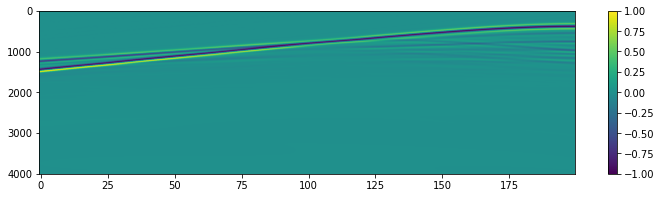

In [195]:
#plot -normalized
plt.figure(figsize=(12, 3))
plt.imshow(batch_rcv_amps_pred_norm[0,:,:], aspect='auto')
plt.colorbar()

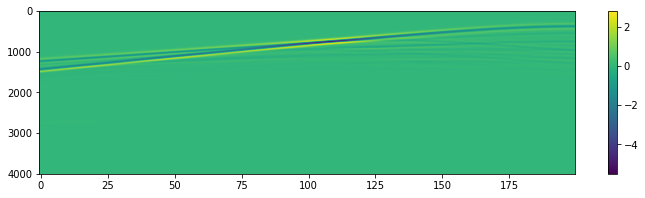

In [196]:
plt.figure(figsize=(12, 3))
plt.imshow(batch_rcv_amps_predTrans[0,:,:], aspect='auto')
plt.colorbar()

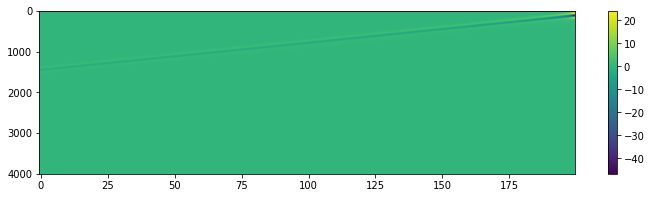

In [197]:
plt.figure(figsize=(12, 3))
plt.imshow(batch_rcv_amps_cte[0,:,:], aspect='auto')
plt.colorbar()

/tmp/ipykernel_19464/2642426928.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap=plt.cm.get_cmap('jet')
/tmp/ipykernel_19464/2642426928.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.ax.set_yticklabels(["{:.1f}".format(i) for i in cbar.get_ticks()],weight='bold')


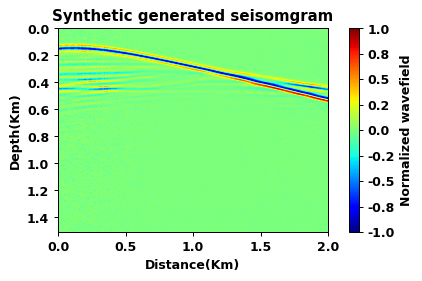

In [19]:
# plt.figure(figsize=(12, 3))
# plt.imshow(batch_rcv_amps_true[0,:,:], aspect='auto')
# plt.colorbar()
maxv=0.8
minv=-0.8
plt.figure(figsize=(6, 3),dpi=90)
cmap=plt.cm.get_cmap('jet')
plt.imshow(batch_rcv_amps_true[0,:,:],vmin=minv,vmax=maxv, cmap=cmap,**par)
plt.title("Synthetic generated seisomgram",weight = 'bold')
cbar=plt.colorbar()
cbar.ax.set_yticklabels(["{:.1f}".format(i) for i in cbar.get_ticks()],weight='bold')
cbar.ax.set_ylabel('Normalized wavefield',weight = 'bold')
plt.xticks(weight = 'bold')
plt.yticks(weight = 'bold')
plt.xlabel('Distance(Km)',weight = 'bold')
plt.ylabel('Depth(Km)',weight = 'bold');

/tmp/ipykernel_19464/220927921.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap=plt.cm.get_cmap('jet')
/tmp/ipykernel_19464/220927921.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.ax.set_yticklabels(["{}".format(i) for i in cbar.get_ticks()],weight='bold')


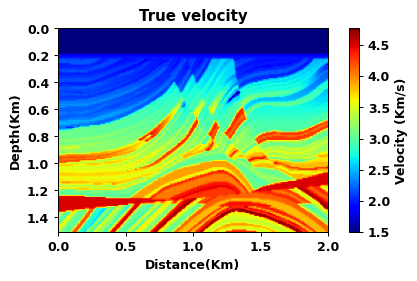

In [4]:
plt.figure(figsize=(6, 3),dpi=90)
cmap=plt.cm.get_cmap('jet')
plt.imshow(true/1000,vmin=min,vmax=max, cmap=cmap,**par)
plt.title("True velocity",weight = 'bold')
cbar=plt.colorbar()
cbar.ax.set_yticklabels(["{}".format(i) for i in cbar.get_ticks()],weight='bold')
cbar.ax.set_ylabel('Velocity (Km/s)',weight = 'bold')
plt.xticks(weight = 'bold')
plt.yticks(weight = 'bold')
plt.xlabel('Distance(Km)',weight = 'bold')
plt.ylabel('Depth(Km)',weight = 'bold');

/tmp/ipykernel_19464/1117314009.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap=plt.cm.get_cmap('jet')
/tmp/ipykernel_19464/1117314009.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.ax.set_yticklabels(["{}".format(i) for i in cbar.get_ticks()],weight='bold')


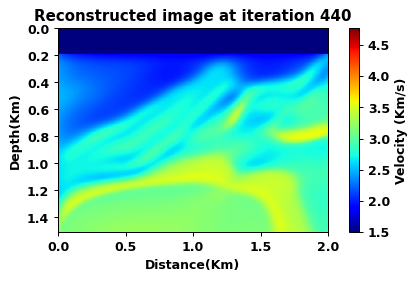

In [15]:
    plt.figure(figsize=(6, 3),dpi=90)
    cmap=plt.cm.get_cmap('jet')
    plt.imshow(model/1000, vmin=min, vmax=max, cmap=cmap,**par)
    plt.title('Reconstructed image at iteration '+str(iter),weight='bold')
    cbar=plt.colorbar()
cbar.ax.set_ylabel('Velocity (Km/s)',weight='bold')
cbar.ax.set_yticklabels(["{}".format(i) for i in cbar.get_ticks()],weight='bold')
plt.xlabel('Distance(Km)',weight='bold');
plt.ylabel('Depth(Km)',weight='bold'); 
plt.xticks(weight = 'bold');
plt.yticks(weight = 'bold');     


/tmp/ipykernel_101696/990687866.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap=plt.cm.get_cmap('jet')
/tmp/ipykernel_101696/990687866.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.ax.set_yticklabels(["{}".format(i) for i in cbar.get_ticks()],weight='bold')


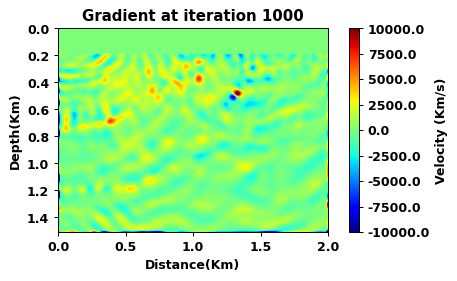

In [202]:
    plt.figure(figsize=(6, 3),dpi=90)
    cmap=plt.cm.get_cmap('jet')
    plt.imshow(grad, vmin=-10000, vmax=10000, cmap=cmap,**par)
    plt.title('Gradient at iteration '+str(iter),weight='bold') 
    cbar=plt.colorbar()
cbar.ax.set_ylabel('Velocity (Km/s)',weight='bold')
cbar.ax.set_yticklabels(["{}".format(i) for i in cbar.get_ticks()],weight='bold')
plt.xlabel('Distance(Km)',weight='bold')
plt.ylabel('Depth(Km)',weight='bold') 
plt.xticks(weight = 'bold')
plt.yticks(weight = 'bold');    

In [203]:
# with open('/disk/utig5/disk/fs4/abdo/PhysicsMLFWI/PhysicsBasedFWI/checkpoints/MarmousiOpenFWI22/loss_log_1.txt') as f:
with open('/disk/utig5/disk/fs4/abdo/PhysicsMLFWI/PhysicsBasedFWI/checkpoints/MarmousiOpenUnet/loss_log.txt') as f:
    
    lines = f.readlines()
epochs = []
mls = []
vls = []
kls = []
dls = []
for i in range(1,len(lines)):
    #print("i:",i)
    po = lines[i].split(')')
    string1 = po[0][1:]
    string2 = po[1]
    result1 = dict((a.strip(), int(b.strip()))  
                         for a, b in (element.split(':')  
                                      for element in string1.split(', ')))  
    epoch = int(result1['epoch'])
    # print("result2 = ",result2)
    result2 = string2.split(' ')
    modelloss = float(result2[2])
    validationloss = float(result2[6])
    # klloss = float(result2[4])
    dlloss = float(result2[4])
    epochs = np.append(epochs,epoch)
    mls = np.append(mls,modelloss)
    vls = np.append(vls,validationloss)
    # kls = np.append(kls,klloss)
    dls = np.append(dls,dlloss)

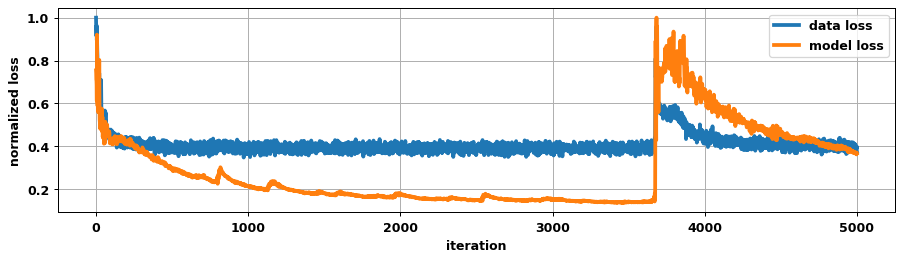

In [205]:
#plt.plot(epochs,mls)
plt.figure(figsize=(12, 3),dpi=90)
plt.plot(epochs,dls/np.max(dls),linewidth=3.0,label='data loss')
plt.plot(epochs,mls/np.max(mls),linewidth=3.0,label='model loss')
plt.xlabel("iteration",weight='bold')
plt.ylabel("normalized loss",weight='bold')
plt.xticks(weight = 'bold')
plt.yticks(weight = 'bold');
legend_properties = {'weight':'bold'}   
plt.legend(prop=legend_properties)
plt.grid()
